In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv
load_dotenv(override=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 

In [ ]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

weekstats = pd.read_csv(DATA_REPO_DIR / "GW1" / "playermatchstats.csv")
players = pd.read_csv(DATA_REPO_DIR / "GW1" / "players.csv")

In [26]:
weekstats = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/playermatchstats.csv")
players = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/players.csv")

In [3]:
spurs_bre = weekstats[
    (weekstats["match_id"] == '26-27-prem-brentford-vs-tottenham-hotspur') & (weekstats["minutes_played"] > 0)
].reset_index(drop=True)

spurs_bre_players = players[(players["team_code"] == 6) | (players["team_code"] == 94)].reset_index(drop=True)
spurs_bre["name"] = spurs_bre["player_id"].map(
    spurs_bre_players.set_index("player_id")["web_name"]
)
spurs_bre["team_code"] = spurs_bre["player_id"].map(
    players.set_index("player_id")["team_code"]
)


In [4]:
x_val_s = spurs_bre[spurs_bre["team_code"] == 6]["accurate_passes"]
y_val_s = spurs_bre[spurs_bre["team_code"] == 6]["final_third_passes"]

x_val_b = spurs_bre[spurs_bre["team_code"] == 94]["accurate_passes"]
y_val_b = spurs_bre[spurs_bre["team_code"] == 94]["final_third_passes"]

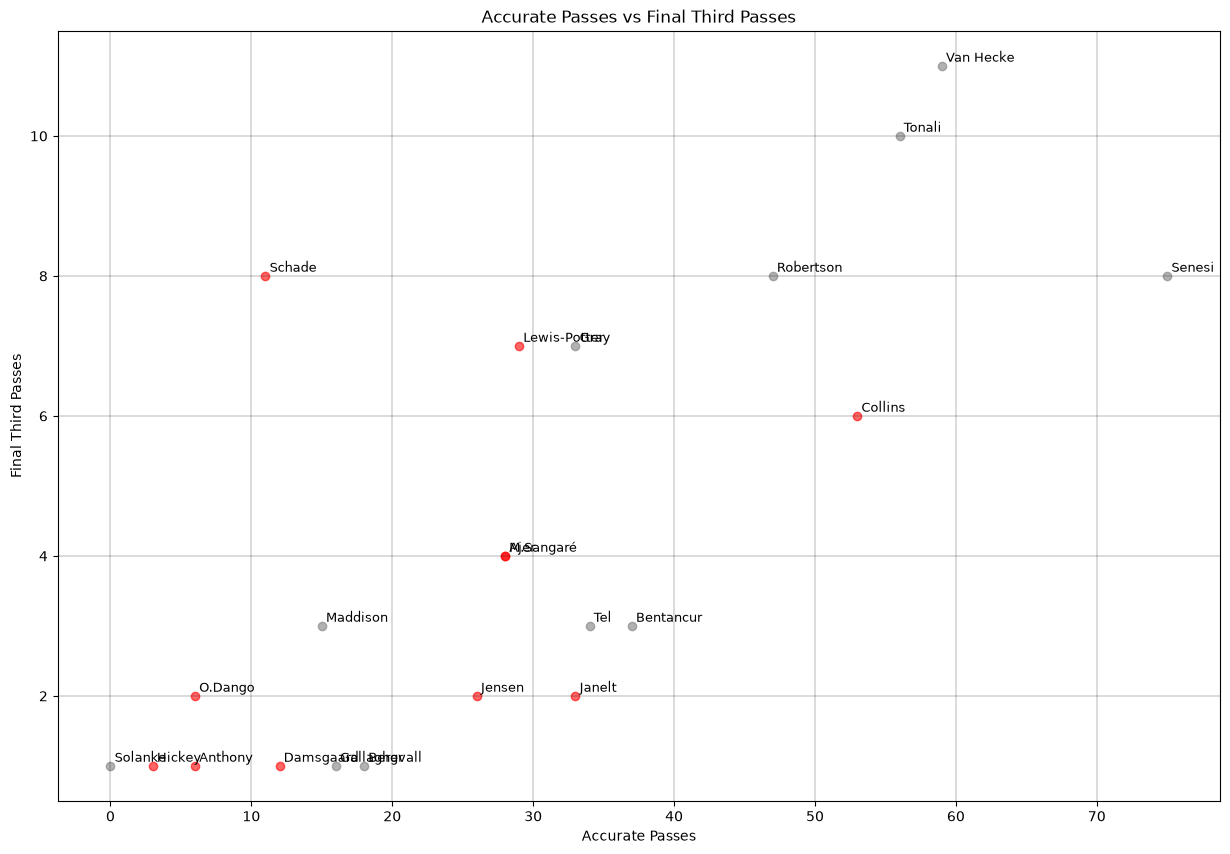

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(x_val_s, y_val_s, alpha=0.6, color="grey")
plt.scatter(x_val_b, y_val_b, alpha=0.6, color="red")

# Add annotations
for _, row in spurs_bre.iterrows():
    plt.annotate(
        row["name"], 
        (row["accurate_passes"], row["final_third_passes"]),
        xytext=(3, 3), 
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel('Accurate Passes')
plt.ylabel('Final Third Passes')
plt.title("Accurate Passes vs Final Third Passes")
plt.grid(color='k', linestyle='-', linewidth=.2)
plt.show()